# T3: Cross-Paper Claim Comparison — Cleaned Structured vs Tuned Semantic

This notebook implements **Task T3** using the final flat T2 output file `t2_structured_claims.jsonl`.

Updated improvements in this version:
1. Removes empty, duplicate, and all-null structured rows before T3.
2. Normalizes `task`, `dataset`, `metric`, and `domain` fields before grouping.
3. Uses strict structured matching with `task + dataset + metric` and cross-paper support.
4. Uses fixed random seeds and tuned UMAP/HDBSCAN defaults for more stable semantic clusters.
5. Saves preprocessing and clustering configuration to `outputs/t3/t3_config.json` for reproducibility.

The two comparison methods remain:
1. **Structured Matching** using strict keys: `task + dataset + metric`
2. **Semantic Similarity (HDBSCAN)** using SPECTER2 embeddings + UMAP + HDBSCAN; if package versions fail, PCA/DBSCAN fallback is used automatically.


In [1]:
# Install required packages (idempotent)
import importlib
import subprocess
import sys

REQUIRED_PACKAGES = [
    ("sentence-transformers", "sentence_transformers"),
    ("scikit-learn", "sklearn"),
    ("hdbscan", "hdbscan"),
    ("umap-learn", "umap"),
    ("numpy", "numpy"),
    ("pandas", "pandas"),
    ("matplotlib", "matplotlib"),
    ("scipy", "scipy"),
    ("ipywidgets", "ipywidgets"),
]

for pkg_name, import_name in REQUIRED_PACKAGES:
    try:
        importlib.import_module(import_name)
        print(f"✓ {pkg_name} already installed")
    except Exception:
        print(f"Installing {pkg_name}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", pkg_name, "-q"])
        print(f"✓ {pkg_name} installed")

/usr/local/lib/python3.10/dist-packages/sentence_transformers/cross_encoder/CrossEncoder.py:11: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm, trange
2026-06-04 10:34:56.662596: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-06-04 10:34:56.662627: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-06-04 10:34:56.663914: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-06-04 10:34:56.671857: I tensorflow/core/platform/cpu_feature_guard.cc:18

✓ sentence-transformers already installed
✓ scikit-learn already installed
✓ hdbscan already installed
✓ umap-learn already installed
✓ numpy already installed
✓ pandas already installed
✓ matplotlib already installed
✓ scipy already installed
✓ ipywidgets already installed


In [2]:
# Core imports and environment guards
import os
import json
import re
import warnings
import random
from collections import defaultdict
from datetime import datetime
from pathlib import Path
from typing import Dict, List, Optional, Tuple, Any

# Force CPU mode to avoid CUDA-driver mismatch warnings/errors on older NVIDIA drivers
os.environ["CUDA_VISIBLE_DEVICES"] = ""

# Suppress noisy environment warnings in notebook runs
warnings.filterwarnings("ignore", message=".*IProgress not found.*")
warnings.filterwarnings("ignore", message=".*CUDA initialization: The NVIDIA driver on your system is too old.*")

import hdbscan
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import umap
from sentence_transformers import SentenceTransformer
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import normalize
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN

warnings.filterwarnings("ignore")

# Reproducibility: UMAP/HDBSCAN-related stages can otherwise change between runs.
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("All imports successful (CPU mode)")

All imports successful (CPU mode)


## Section 1: Load Final T2 Structured Claims

This section loads the final T2 flat JSONL output (`t2_structured_claims.jsonl`) and prepares it for the two original T3 comparison methods.


In [3]:
# Load final flat T2 structured claims JSONL
# Expected schema from T2:
# paper_id, sentence_id, title, year, claim_text, raw_sentence, text,
# model, task, dataset, metric, value, comparison, domain

WORKSPACE_ROOT = Path.cwd()

MANUAL_DATA_PATH = Path("/work/Research/MedClaimExtractor/outputs/t2/t2_structured_claims.jsonl")

candidate_paths = [
    MANUAL_DATA_PATH,
    WORKSPACE_ROOT / "outputs" / "t2" / "t2_structured_claims.jsonl",
    WORKSPACE_ROOT.parent / "outputs" / "t2" / "t2_structured_claims.jsonl",
]

DATA_PATH = None
for path in candidate_paths:
    if path.exists():
        DATA_PATH = path
        break

if DATA_PATH is None:
    print("Checked these paths:")
    for path in candidate_paths:
        print(" -", path)
    raise FileNotFoundError("t2_structured_claims.jsonl not found. Set MANUAL_DATA_PATH to the correct file.")

print(f"✓ T2 structured claims found: {DATA_PATH}")

def clean_value(v):
    if v is None:
        return None
    if isinstance(v, float) and pd.isna(v):
        return None
    t = str(v).strip()
    if not t or t.lower() in {"none", "null", "nan", "n/a", ""}:
        return None
    return t

def read_jsonl(path):
    rows = []
    with open(path, "r", encoding="utf-8") as f:
        for line_no, line in enumerate(f, 1):
            line = line.strip()
            if not line:
                continue
            try:
                rows.append(json.loads(line))
            except Exception as e:
                raise ValueError(f"Bad JSON at line {line_no} in {path}: {e}")
    return rows

raw_records = read_jsonl(DATA_PATH)
print(f"Raw JSONL records loaded: {len(raw_records)}")

# Support both final flat T2 output and older paper-level JSONL, but prefer flat output.
rows = []

if raw_records and isinstance(raw_records[0], dict) and "sentences" in raw_records[0]:
    # Older nested paper-level format
    for paper in raw_records:
        paper_id = paper.get("paper_id") or paper.get("doi") or "unknown"
        title = paper.get("title", "")
        year = paper.get("year", None)
        for sent in paper.get("sentences", []):
            if not isinstance(sent, dict):
                continue
            if int(sent.get("label", sent.get("predicted_label", 1)) or 0) != 1:
                continue
            structured_info = sent.get("structured_info") or {}
            claim_text = str(sent.get("claim_text") or sent.get("text") or sent.get("raw_sentence") or "").strip()
            rows.append({
                "paper_id": str(paper_id),
                "sentence_id": sent.get("sentence_id"),
                "title": str(title),
                "year": year,
                "claim_text": claim_text,
                "raw_sentence": claim_text,
                "text": f"[{year}] {title} | {claim_text}",
                "model": clean_value(structured_info.get("model")),
                "task": clean_value(structured_info.get("task")),
                "dataset": clean_value(structured_info.get("dataset")),
                "metric": clean_value(structured_info.get("metric")),
                "value": clean_value(structured_info.get("value")),
                "comparison": clean_value(structured_info.get("comparison")),
                "domain": clean_value(structured_info.get("domain")),
            })
else:
    # Final flat T2 format
    for rec in raw_records:
        if not isinstance(rec, dict):
            continue
        paper_id = rec.get("paper_id") or rec.get("doi") or "unknown"
        title = rec.get("title") or ""
        year = rec.get("year")
        claim_text = str(rec.get("claim_text") or rec.get("raw_sentence") or rec.get("text") or "").strip()
        raw_sentence = str(rec.get("raw_sentence") or claim_text).strip()
        combined_text = rec.get("text") or f"[{year}] {title} | {claim_text}"
        rows.append({
            "paper_id": str(paper_id),
            "sentence_id": rec.get("sentence_id"),
            "title": str(title),
            "year": year,
            "claim_text": claim_text,
            "raw_sentence": raw_sentence,
            "text": combined_text,
            "model": clean_value(rec.get("model")),
            "task": clean_value(rec.get("task")),
            "dataset": clean_value(rec.get("dataset")),
            "metric": clean_value(rec.get("metric")),
            "value": clean_value(rec.get("value")),
            "comparison": clean_value(rec.get("comparison")),
            "domain": clean_value(rec.get("domain")),
        })

df_claims = pd.DataFrame(rows)

# Drop rows with empty claim text because semantic similarity needs text.
if len(df_claims) > 0:
    before = len(df_claims)
    df_claims = df_claims[df_claims["raw_sentence"].notna()].copy()
    df_claims = df_claims[df_claims["raw_sentence"].astype(str).str.strip() != ""].copy()
    df_claims = df_claims.reset_index(drop=True)
    print(f"Dropped empty claim-text rows: {before - len(df_claims)}")

print(f"Claim rows prepared for T3: {len(df_claims)}")
print(f"Columns: {df_claims.columns.tolist()}")

if len(df_claims) > 0:
    print("\nSample T2 claim row:")
    print(df_claims.iloc[0].to_dict())

# Short sanity check for the issue discussed: clusters are based on task+dataset+metric combinations, not datasets alone.
if len(df_claims) > 0:
    n_datasets = df_claims["dataset"].dropna().nunique()
    n_task_metric = df_claims[["task", "metric"]].dropna().drop_duplicates().shape[0]
    n_strict_keys = df_claims[["task", "dataset", "metric"]].dropna().drop_duplicates().shape[0]
    print("\nStructured-field sanity:")
    print(f"  Unique extracted datasets: {n_datasets}")
    print(f"  Unique task+metric pairs: {n_task_metric}")
    print(f"  Unique strict task+dataset+metric keys: {n_strict_keys}")



✓ T2 structured claims found: /work/Research/extracted/Nawazish_RnD/Notebook/outputs/t2/t2_structured_claims.jsonl
Raw JSONL records loaded: 7564
Dropped empty claim-text rows: 0
Claim rows prepared for T3: 7564
Columns: ['paper_id', 'sentence_id', 'title', 'year', 'claim_text', 'raw_sentence', 'text', 'model', 'task', 'dataset', 'metric', 'value', 'comparison', 'domain']

Sample T2 claim row:
{'paper_id': '10.1002/cncr.35732', 'sentence_id': 5, 'title': '', 'year': 2025, 'claim_text': 'All 35 individuals were participants in the University of California, San Francisco Adult Glioma Study.Results: There was a positive correlation among firefighters between the median number of sample variants attributable to single-base substitution signature 42, a single-base substitution mutational signature associated with haloalkane exposure (from the Catalogue of Somatic Mutational Signatures in Cancer) and firefighting years (p = .04; R2 = 0.29).', 'raw_sentence': 'All 35 individuals were particip

In [4]:
# Clean, normalize, and retain only reliable T3 claim rows
# This section is the main fix for unstable results like "3 semantic clusters" or inflated Precision@K.

SLOT_KEYS = ["model", "task", "dataset", "metric", "value", "comparison", "domain"]

# Preprocessing switches
MIN_CLAIM_CHARS = 20
DROP_DUPLICATE_CLAIMS = True
DROP_ALL_NULL_STRUCTURED_ROWS = True

MISSING_STRINGS = {"", "none", "null", "nan", "n/a", "na", "-", "--", "not specified", "unknown"}

def is_missing_value(v) -> bool:
    if v is None:
        return True
    if isinstance(v, float) and pd.isna(v):
        return True
    text = str(v).strip()
    return text.lower() in MISSING_STRINGS

def normalize_text(value: Optional[str]) -> Optional[str]:
    """Lowercase, remove noisy spacing/punctuation variants, and return None for empty values."""
    if is_missing_value(value):
        return None
    text = str(value).strip().lower()
    text = text.replace("_", " ").replace("-", " ")
    text = re.sub(r"[()\[\]{}]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text or None

METRIC_ALIASES = {
    # segmentation
    "dice": "dice",
    "dice score": "dice",
    "dice coefficient": "dice",
    "dice similarity coefficient": "dice",
    "dsc": "dice",
    "mean dice": "dice",
    "iou": "iou",
    "jaccard": "iou",
    "jaccard index": "iou",
    "intersection over union": "iou",
    "hausdorff distance": "hd95",
    "hd95": "hd95",
    "95 hausdorff distance": "hd95",
    # classification / diagnosis
    "accuracy": "accuracy",
    "acc": "accuracy",
    "classification accuracy": "accuracy",
    "auc": "auc-roc",
    "roc auc": "auc-roc",
    "auc roc": "auc-roc",
    "auc-roc": "auc-roc",
    "roc-auc": "auc-roc",
    "area under the curve": "auc-roc",
    "f1": "f1",
    "f1 score": "f1",
    "f1-score": "f1",
    "precision": "precision",
    "recall": "recall",
    "sensitivity": "sensitivity",
    "specificity": "specificity",
    # survival / statistics
    "c index": "c-index",
    "c-index": "c-index",
    "concordance index": "c-index",
    "hazard ratio": "hazard-ratio",
    "hr": "hazard-ratio",
    "odds ratio": "odds-ratio",
    "or": "odds-ratio",
    "p value": "p-value",
    "p-value": "p-value",
}

DATASET_ALIASES = {
    "brats": "brats",
    "brats 2018": "brats 2018",
    "brats2018": "brats 2018",
    "brats 2019": "brats 2019",
    "brats2019": "brats 2019",
    "brats 2020": "brats 2020",
    "brats2020": "brats 2020",
    "brats 2021": "brats 2021",
    "brats2021": "brats 2021",
    "brats 2022": "brats 2022",
    "brats2022": "brats 2022",
    "brats 2023": "brats 2023",
    "brats2023": "brats 2023",
    "brats 2024": "brats 2024",
    "brats2024": "brats 2024",
    "tcga": "tcga",
    "tcia": "tcia",
    "cbioportal": "cbioportal",
    "c bioportal": "cbioportal",
    "figshare": "figshare",
    "kaggle": "kaggle",
    "kaggle brain tumor mri": "kaggle brain tumor mri",
    "brain tumor segmentation challenge": "brats",
}

# Values that often appear in the extracted dataset field but are not dataset names.
BAD_DATASET_TERMS = {
    "patients", "patient", "cases", "case", "subjects", "participants",
    "images", "mri images", "studies", "cohort", "training set", "test set",
}

BAD_METRIC_TERMS = {
    # broad concepts that should not be used as formal metrics
    "expression", "survival", "grade", "tumor grade", "level", "pathway",
    "functional connectivity", "classification", "segmentation",
}

def canonical_metric(metric: Optional[str]) -> Optional[str]:
    m = normalize_text(metric)
    if m is None:
        return None

    # Handle multi-metric outputs such as "accuracy, sensitivity, specificity"
    pieces = [p.strip() for p in re.split(r"[,;/|]+|\band\b", m) if p.strip()]
    if len(pieces) > 1:
        normed = []
        for p in pieces:
            p = METRIC_ALIASES.get(p, p)
            if p not in BAD_METRIC_TERMS:
                normed.append(p)
        normed = sorted(set(normed))
        return ", ".join(normed) if normed else None

    m = METRIC_ALIASES.get(m, m)
    if m in BAD_METRIC_TERMS:
        return None
    return m

def canonical_dataset(dataset: Optional[str]) -> Optional[str]:
    d = normalize_text(dataset)
    if d is None:
        return None
    if d in BAD_DATASET_TERMS:
        return None
    return DATASET_ALIASES.get(d, d)

def canonical_task(task: Optional[str]) -> Optional[str]:
    t = normalize_text(task)
    if t is None:
        return None
    # light normalization only; keep task meaning intact
    task_aliases = {
        "tumor segmentation": "brain tumor segmentation",
        "brain tumour segmentation": "brain tumor segmentation",
        "glioma segmentation": "glioma segmentation",
        "brain tumor classification": "brain tumor classification",
        "brain tumour classification": "brain tumor classification",
        "glioma classification": "glioma classification",
        "survival prediction": "survival prediction",
        "overall survival prediction": "survival prediction",
        "grading": "tumor grading",
        "tumor grading": "tumor grading",
        "glioma grading": "glioma grading",
    }
    return task_aliases.get(t, t)

def canonical_domain(domain: Optional[str]) -> Optional[str]:
    return normalize_text(domain)

def row_all_structured_null(row: pd.Series) -> bool:
    return all(is_missing_value(row.get(k)) for k in SLOT_KEYS)

# Keep a copy of the raw loaded table for audit.
df_claims_raw_loaded = df_claims.copy()
initial_rows = len(df_claims)

# 1) Remove empty / too-short claim text rows.
if len(df_claims) > 0:
    text_series = df_claims["raw_sentence"].fillna("").astype(str).str.strip()
    keep_text = text_series.str.len() >= MIN_CLAIM_CHARS
    df_claims = df_claims[keep_text].copy()

# 2) Drop exact duplicate claim rows from the same paper.
duplicates_removed = 0
if DROP_DUPLICATE_CLAIMS and len(df_claims) > 0:
    before = len(df_claims)
    df_claims["_dedupe_text"] = df_claims["raw_sentence"].fillna("").astype(str).str.lower().str.strip()
    df_claims = df_claims.drop_duplicates(subset=["paper_id", "_dedupe_text"]).copy()
    df_claims = df_claims.drop(columns=["_dedupe_text"])
    duplicates_removed = before - len(df_claims)

# 3) Remove all-null structured rows. These are usually not useful for T3 comparison
# and often inflate outlier counts in semantic clustering.
all_null_removed = 0
if DROP_ALL_NULL_STRUCTURED_ROWS and len(df_claims) > 0:
    before = len(df_claims)
    df_claims = df_claims[~df_claims.apply(row_all_structured_null, axis=1)].copy()
    all_null_removed = before - len(df_claims)

# 4) Add normalized columns used by both structured matching and fair diagnostics.
if len(df_claims) > 0:
    df_claims["task_norm"] = df_claims["task"].apply(canonical_task)
    df_claims["dataset_norm"] = df_claims["dataset"].apply(canonical_dataset)
    df_claims["metric_norm"] = df_claims["metric"].apply(canonical_metric)
    df_claims["domain_norm"] = df_claims["domain"].apply(canonical_domain)

df_claims = df_claims.reset_index(drop=True)

T3_PREPROCESSING_SUMMARY = {
    "initial_rows_loaded": int(initial_rows),
    "rows_after_cleaning": int(len(df_claims)),
    "short_or_empty_text_removed": int(initial_rows - len(df_claims_raw_loaded[df_claims_raw_loaded["raw_sentence"].fillna("").astype(str).str.strip().str.len() >= MIN_CLAIM_CHARS])),
    "duplicate_claims_removed": int(duplicates_removed),
    "all_null_structured_rows_removed": int(all_null_removed),
    "min_claim_chars": int(MIN_CLAIM_CHARS),
    "drop_duplicate_claims": bool(DROP_DUPLICATE_CLAIMS),
    "drop_all_null_structured_rows": bool(DROP_ALL_NULL_STRUCTURED_ROWS),
}

print("T3 preprocessing summary:")
print(json.dumps(T3_PREPROCESSING_SUMMARY, indent=2))

# Inspect structured field coverage after cleaning.
coverage = {}
for key in SLOT_KEYS + ["task_norm", "dataset_norm", "metric_norm", "domain_norm"]:
    non_null = int(df_claims[key].notna().sum()) if key in df_claims.columns else 0
    coverage[key] = {
        "non_null": non_null,
        "pct": (100.0 * non_null / len(df_claims)) if len(df_claims) else 0.0,
    }

coverage_df = pd.DataFrame(coverage).T.sort_values("pct", ascending=False)
print("\nStructured field coverage after T3 cleaning:")
print(coverage_df.to_string())

# Strict fields needed for structured comparison.
strict_ready = (
    df_claims[["task_norm", "dataset_norm", "metric_norm"]]
    .notna()
    .all(axis=1)
    .sum()
    if len(df_claims) else 0
)
print(f"\nClaims ready for strict structured matching (task+dataset+metric): {strict_ready}")
print(f"Claims used for semantic clustering after cleaning: {len(df_claims)}")

# Keep records as dictionaries for matching and semantic stages
claims_list = df_claims.to_dict(orient="records")
print(f"\nPrepared {len(claims_list)} cleaned claim records for comparison")


T3 preprocessing summary:
{
  "initial_rows_loaded": 7564,
  "rows_after_cleaning": 7564,
  "short_or_empty_text_removed": 0,
  "duplicate_claims_removed": 0,
  "all_null_structured_rows_removed": 0,
  "min_claim_chars": 20,
  "drop_duplicate_claims": true,
  "drop_all_null_structured_rows": true
}

Structured field coverage after T3 cleaning:
              non_null         pct
model           7564.0  100.000000
metric          3032.0   40.084611
task            2956.0   39.079852
task_norm       2956.0   39.079852
domain          2761.0   36.501851
domain_norm     2761.0   36.501851
metric_norm     2373.0   31.372290
value           1349.0   17.834479
comparison      1141.0   15.084611
dataset          824.0   10.893707
dataset_norm     824.0   10.893707

Claims ready for strict structured matching (task+dataset+metric): 153
Claims used for semantic clustering after cleaning: 7564

Prepared 7564 cleaned claim records for comparison


## Section 2: Implement Structured Matching

Structured matching uses hard constraints on task, dataset, and domain fields to identify comparable claims.

In [5]:
class StructuredMatcher:
    """
    Strict structured matcher.

    Claims are comparable only when normalized task + dataset + metric match.
    Requiring normalized fields avoids weak clusters built from noisy raw strings.
    """

    def __init__(self, min_group_size: int = 2, require_cross_paper: bool = True):
        self.min_group_size = min_group_size
        self.require_cross_paper = require_cross_paper

    def build_group_key(self, claim: Dict) -> Optional[Tuple[str, str, str]]:
        task = claim.get("task_norm") or canonical_task(claim.get("task"))
        dataset = claim.get("dataset_norm") or canonical_dataset(claim.get("dataset"))
        metric = claim.get("metric_norm") or canonical_metric(claim.get("metric"))

        if not task or not dataset or not metric:
            return None
        return (task, dataset, metric)

    def build_comparison_groups(self, claims: List[Dict]) -> Dict[Tuple[str, str, str], List[int]]:
        groups = defaultdict(list)
        for idx, claim in enumerate(claims):
            key = self.build_group_key(claim)
            if key is not None:
                groups[key].append(idx)

        filtered = {}
        for key, indices in groups.items():
            if len(indices) < self.min_group_size:
                continue

            if self.require_cross_paper:
                paper_ids = {
                    str(claims[i].get("paper_id", "unknown"))
                    for i in indices
                    if claims[i].get("paper_id") is not None
                }
                if len(paper_ids) < 2:
                    continue

            filtered[key] = indices

        return filtered

matcher = StructuredMatcher(min_group_size=2, require_cross_paper=True)
structured_groups = matcher.build_comparison_groups(claims_list)

print(f"Comparable structured groups found: {len(structured_groups)}")
if structured_groups:
    sizes = sorted([len(v) for v in structured_groups.values()], reverse=True)
    print(f"Largest group sizes: {sizes[:10]}")
    sample_key = next(iter(structured_groups.keys()))
    print(f"Sample group key (task, dataset, metric): {sample_key}")
else:
    print("No strict structured groups found. Check task_norm, dataset_norm, and metric_norm coverage above.")


Comparable structured groups found: 6
Largest group sizes: [3, 3, 2, 2, 2, 2]
Sample group key (task, dataset, metric): ('survival prediction', 'gbm patients', 'overall survival')


## Section 3: Implement Semantic Similarity

Semantic similarity uses SPECTER2 embeddings to rank comparable claims based on semantic relevance.

In [6]:
# Load embedding model (prefer SPECTER2 per revised plan)
print("Loading SPECTER2 model in CPU mode... this can take a minute")
try:
    specter_model = SentenceTransformer("allenai/specter2_base", device="cpu")
    print("✓ SPECTER2 model loaded (CPU)")
except Exception as e:
    print(f"SPECTER2 unavailable, using fallback model: {e}")
    specter_model = SentenceTransformer("all-mpnet-base-v2", device="cpu")
    print("✓ Fallback model loaded (CPU)")

Loading SPECTER2 model in CPU mode... this can take a minute


No sentence-transformers model found with name allenai/specter2_base. Creating a new one with mean pooling.


✓ SPECTER2 model loaded (CPU)


In [7]:
class SemanticSimilarityMatcher:
    """
    Embedding-based semantic matcher.

    Improvements in this version:
    - fixed random_state
    - tunable UMAP n_neighbors/min_dist/n_components
    - tuned HDBSCAN parameters
    - optional fallback to PCA/DBSCAN if local package versions fail
    """

    def __init__(self, model):
        self.model = model
        self.embeddings = None
        self.embeddings_reduced = None
        self.similarity_matrix = None
        self.reduction_method = None
        self.clustering_method = None
        self.last_config = {}

    def _claim_to_text(self, claim: Dict) -> str:
        # Use clean sentence text as the core. Add normalized fields only when available.
        parts = [
            f"Title: {claim.get('title') or ''}",
            f"Sentence: {claim.get('raw_sentence') or claim.get('claim_text') or claim.get('text') or ''}",
        ]

        structured_bits = []
        for label, key in [
            ("Task", "task_norm"),
            ("Dataset", "dataset_norm"),
            ("Metric", "metric_norm"),
            ("Domain", "domain_norm"),
        ]:
            if claim.get(key):
                structured_bits.append(f"{label}: {claim.get(key)}")

        if structured_bits:
            parts.append(" | ".join(structured_bits))

        return " | ".join(parts)

    def generate_embeddings(self, claims: List[Dict]) -> np.ndarray:
        texts = [self._claim_to_text(c) for c in claims]
        print(f"Generating embeddings for {len(texts)} cleaned claims...")
        self.embeddings = self.model.encode(texts, show_progress_bar=True)
        self.embeddings = np.asarray(self.embeddings, dtype=np.float32)
        print(f"Embeddings shape: {self.embeddings.shape}")
        return self.embeddings

    def compute_similarity_matrix(self) -> np.ndarray:
        if self.embeddings is None:
            raise ValueError("Call generate_embeddings first")
        emb_norm = normalize(self.embeddings, norm="l2")
        self.similarity_matrix = np.dot(emb_norm, emb_norm.T)
        np.fill_diagonal(self.similarity_matrix, 1.0)
        return self.similarity_matrix

    def reduce_embeddings(
        self,
        n_components: int = 10,
        n_neighbors: int = 15,
        min_dist: float = 0.05,
    ) -> np.ndarray:
        """Try UMAP first; if it fails due to version mismatch, use PCA fallback."""
        if self.embeddings is None:
            raise ValueError("Call generate_embeddings first")

        n_components = int(min(
            n_components,
            max(2, self.embeddings.shape[1]),
            max(2, self.embeddings.shape[0] - 1),
        ))

        n_neighbors = int(min(max(2, n_neighbors), max(2, self.embeddings.shape[0] - 1)))

        try:
            print("Reducing dimensionality with tuned UMAP...")
            reducer = umap.UMAP(
                n_neighbors=n_neighbors,
                n_components=n_components,
                min_dist=min_dist,
                metric="cosine",
                random_state=SEED,
            )
            self.embeddings_reduced = reducer.fit_transform(self.embeddings)
            self.reduction_method = "UMAP"
        except Exception as e:
            print("⚠️ UMAP failed because of package-version mismatch or runtime issue:", e)
            print("Falling back to PCA for dimensionality reduction...")
            reducer = PCA(n_components=n_components, random_state=SEED)
            self.embeddings_reduced = reducer.fit_transform(self.embeddings)
            self.reduction_method = "PCA fallback"

        self.embeddings_reduced = np.asarray(self.embeddings_reduced, dtype=np.float32)
        print(f"Reduction method used: {self.reduction_method}")
        print(f"Reduced embeddings shape: {self.embeddings_reduced.shape}")
        return self.embeddings_reduced

    def _patch_hdbscan_check_array(self):
        """Patch old hdbscan with newer scikit-learn naming if possible."""
        try:
            import hdbscan.hdbscan_ as hdbscan_module
            from sklearn.utils.validation import check_array as sklearn_check_array

            def check_array_compat(*args, ensure_all_finite=None, **kwargs):
                if ensure_all_finite is not None and "force_all_finite" not in kwargs:
                    kwargs["force_all_finite"] = ensure_all_finite
                return sklearn_check_array(*args, **kwargs)

            hdbscan_module.check_array = check_array_compat
        except Exception as e:
            print("Could not apply HDBSCAN compatibility patch:", e)

    def _fallback_dbscan(self, min_samples: int = 3, eps: float = 0.75) -> Tuple[np.ndarray, np.ndarray]:
        """DBSCAN fallback when HDBSCAN is broken in the local environment."""
        print("Falling back to sklearn DBSCAN clustering...")

        clusterer = DBSCAN(eps=eps, min_samples=min_samples, metric="euclidean")
        labels = clusterer.fit_predict(self.embeddings_reduced)

        probabilities = np.where(labels == -1, 0.0, 1.0).astype(float)
        self.clustering_method = "DBSCAN fallback"
        return labels, probabilities

    def cluster_with_hdbscan(
        self,
        umap_components: int = 10,
        umap_n_neighbors: int = 15,
        umap_min_dist: float = 0.05,
        min_cluster_size: int = 8,
        min_samples: int = 3,
        cluster_selection_method: str = "eom",
        cluster_selection_epsilon: float = 0.0,
        dbscan_eps: float = 0.75,
    ) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
        if self.embeddings is None:
            raise ValueError("Call generate_embeddings first")

        self.last_config = {
            "umap_components": int(umap_components),
            "umap_n_neighbors": int(umap_n_neighbors),
            "umap_min_dist": float(umap_min_dist),
            "min_cluster_size": int(min_cluster_size),
            "min_samples": int(min_samples),
            "cluster_selection_method": cluster_selection_method,
            "cluster_selection_epsilon": float(cluster_selection_epsilon),
            "dbscan_eps": float(dbscan_eps),
            "random_state": int(SEED),
        }

        self.reduce_embeddings(
            n_components=umap_components,
            n_neighbors=umap_n_neighbors,
            min_dist=umap_min_dist,
        )

        try:
            print("Clustering with tuned HDBSCAN...")
            self._patch_hdbscan_check_array()
            clusterer = hdbscan.HDBSCAN(
                min_cluster_size=min_cluster_size,
                min_samples=min_samples,
                metric="euclidean",
                cluster_selection_method=cluster_selection_method,
                cluster_selection_epsilon=cluster_selection_epsilon,
                prediction_data=False,
            )
            labels = clusterer.fit_predict(self.embeddings_reduced)
            probabilities = clusterer.probabilities_
            self.clustering_method = "HDBSCAN"
        except Exception as e:
            print("⚠️ HDBSCAN failed because of package-version mismatch or runtime issue:", e)
            labels, probabilities = self._fallback_dbscan(min_samples=min_samples, eps=dbscan_eps)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = int(np.sum(labels == -1))
        noise_ratio = n_noise / len(labels) if len(labels) else 0.0
        print(f"Clustering method used: {self.clustering_method}")
        print(f"Clusters: {n_clusters} | Noise points: {n_noise} | Noise ratio: {noise_ratio:.3f}")
        print("Config:", json.dumps(self.last_config, indent=2))
        return labels, probabilities, self.embeddings_reduced

semantic_matcher = SemanticSimilarityMatcher(specter_model)
embeddings = semantic_matcher.generate_embeddings(claims_list)
similarity_matrix = semantic_matcher.compute_similarity_matrix()
print("✓ Semantic similarity matrix ready")


Generating embeddings for 7564 cleaned claims...


Batches:   0%|          | 0/237 [00:00<?, ?it/s]

Embeddings shape: (7564, 768)
✓ Semantic similarity matrix ready


## Section 4: Evaluate Structured Matching Performance

Evaluate structured matching using clustering metrics and precision@K.

In [8]:
def evaluate_clustering(labels: np.ndarray, similarity_matrix: np.ndarray, method_name: str) -> Dict:
    valid_mask = labels != -1
    valid_labels = labels[valid_mask]

    metrics = {
        "method": method_name,
        "n_clusters": len(set(labels)) - (1 if -1 in labels else 0),
        "n_noise_points": int(np.sum(labels == -1)),
        "noise_ratio": float(np.mean(labels == -1)) if len(labels) else 0.0,
        "total_points": len(labels),
        "silhouette_score": None,
    }

    if metrics["n_clusters"] > 1 and np.sum(valid_mask) > 2:
        try:
            distance_matrix = 1 - similarity_matrix
            np.fill_diagonal(distance_matrix, 0.0)
            sub = distance_matrix[np.ix_(valid_mask, valid_mask)]
            metrics["silhouette_score"] = float(
                silhouette_score(sub, valid_labels, metric="precomputed")
            )
        except Exception as e:
            print(f"Silhouette not available for {method_name}: {e}")

    return metrics

def compute_cluster_consistency_precision_at_k(labels: np.ndarray, similarity_matrix: np.ndarray, k: int = 5) -> float:
    """
    Original-style Precision@K:
    for each clustered claim, check whether its top-K semantic neighbours fall in the same cluster.
    This is useful for comparing cluster compactness, but it favors embedding-based clusters.
    """
    precisions = []
    for i in range(len(labels)):
        if labels[i] == -1:
            continue
        sims = similarity_matrix[i]
        top_k_indices = np.argsort(sims)[::-1][1 : k + 1]
        if len(top_k_indices) == 0:
            continue
        same_cluster = np.sum(labels[top_k_indices] == labels[i])
        precisions.append(same_cluster / len(top_k_indices))
    return float(np.mean(precisions)) if precisions else 0.0

def claims_are_field_relevant(a: Dict, b: Dict) -> bool:
    """
    Field-based relevance rule for fair diagnostics.
    This is independent of HDBSCAN labels and prevents over-crediting very broad semantic clusters.
    """
    task_a, task_b = a.get("task_norm"), b.get("task_norm")
    data_a, data_b = a.get("dataset_norm"), b.get("dataset_norm")
    metric_a, metric_b = a.get("metric_norm"), b.get("metric_norm")
    domain_a, domain_b = a.get("domain_norm"), b.get("domain_norm")

    same_task_metric = bool(task_a and task_b and metric_a and metric_b and task_a == task_b and metric_a == metric_b)
    same_dataset_metric = bool(data_a and data_b and metric_a and metric_b and data_a == data_b and metric_a == metric_b)
    same_domain_plus_metric = bool(domain_a and domain_b and metric_a and metric_b and domain_a == domain_b and metric_a == metric_b)

    return same_task_metric or same_dataset_metric or same_domain_plus_metric

def compute_field_relevance_precision_at_k(
    labels: np.ndarray,
    similarity_matrix: np.ndarray,
    claims: List[Dict],
    k: int = 5,
) -> float:
    """
    Fairer Precision@K:
    for each clustered claim, retrieve top-K neighbours from the same method cluster,
    ranked by semantic similarity, then check normalized field relevance.
    """
    precisions = []
    for i in range(len(labels)):
        if labels[i] == -1:
            continue

        same_label_indices = np.where(labels == labels[i])[0]
        same_label_indices = same_label_indices[same_label_indices != i]

        if len(same_label_indices) == 0:
            continue

        ranked = same_label_indices[np.argsort(similarity_matrix[i, same_label_indices])[::-1]]
        top_k = ranked[:k]
        if len(top_k) == 0:
            continue

        correct = sum(claims_are_field_relevant(claims[i], claims[j]) for j in top_k)
        precisions.append(correct / len(top_k))

    return float(np.mean(precisions)) if precisions else 0.0

print("=" * 60)
print("STRUCTURED MATCHING EVALUATION")
print("=" * 60)

labels_structured = np.full(len(claims_list), -1, dtype=int)
comparison_groups_sm = list(structured_groups.values())
for group_idx, group_members in enumerate(comparison_groups_sm):
    for claim_idx in group_members:
        labels_structured[claim_idx] = group_idx

print(f"Comparable groups: {len(comparison_groups_sm)}")
if comparison_groups_sm:
    print(f"First group size: {len(comparison_groups_sm[0])}")

eval_structured = evaluate_clustering(
    labels_structured,
    similarity_matrix,
    method_name="Structured Matching (task+dataset+metric)",
)

precision_k_5_sm = compute_cluster_consistency_precision_at_k(labels_structured, similarity_matrix, k=5)
precision_k_10_sm = compute_cluster_consistency_precision_at_k(labels_structured, similarity_matrix, k=10)
field_precision_k_5_sm = compute_field_relevance_precision_at_k(labels_structured, similarity_matrix, claims_list, k=5)
field_precision_k_10_sm = compute_field_relevance_precision_at_k(labels_structured, similarity_matrix, claims_list, k=10)

print("\nStructured Matching Results:")
print(eval_structured)
print(f"Cluster-consistency Precision@5: {precision_k_5_sm:.4f}")
print(f"Cluster-consistency Precision@10: {precision_k_10_sm:.4f}")
print(f"Field-relevance Precision@5: {field_precision_k_5_sm:.4f}")
print(f"Field-relevance Precision@10: {field_precision_k_10_sm:.4f}")


STRUCTURED MATCHING EVALUATION
Comparable groups: 6
First group size: 2

Structured Matching Results:
{'method': 'Structured Matching (task+dataset+metric)', 'n_clusters': 6, 'n_noise_points': 7550, 'noise_ratio': 0.9981491274457959, 'total_points': 7564, 'silhouette_score': 0.21824121475219727}
Cluster-consistency Precision@5: 0.0714
Cluster-consistency Precision@10: 0.0500
Field-relevance Precision@5: 1.0000
Field-relevance Precision@10: 1.0000


## Section 5: Evaluate Semantic Similarity Performance

Evaluate HDBSCAN clustering on SPECTER2 embeddings using clustering metrics and precision@K.

In [9]:
print("\n" + "=" * 60)
print("SEMANTIC SIMILARITY EVALUATION (SPECTER2 + tuned UMAP + HDBSCAN)")
print("=" * 60)

# Tuned defaults chosen to avoid extremely broad 2-3 cluster solutions.
# Adjust only if the output has too few clusters or too many outliers.
SEMANTIC_CLUSTER_CONFIG = {
    "umap_components": 10,
    "umap_n_neighbors": 15,
    "umap_min_dist": 0.05,
    "min_cluster_size": 8,
    "min_samples": 3,
    "cluster_selection_method": "eom",
    "cluster_selection_epsilon": 0.0,
    "dbscan_eps": 0.75,
}

labels_semantic_hdbscan, probs_hdbscan, embeddings_reduced = semantic_matcher.cluster_with_hdbscan(
    **SEMANTIC_CLUSTER_CONFIG
)

eval_semantic = evaluate_clustering(
    labels_semantic_hdbscan,
    similarity_matrix,
    method_name="Semantic Similarity (HDBSCAN)",
)

precision_k_5_sem = compute_cluster_consistency_precision_at_k(labels_semantic_hdbscan, similarity_matrix, k=5)
precision_k_10_sem = compute_cluster_consistency_precision_at_k(labels_semantic_hdbscan, similarity_matrix, k=10)
field_precision_k_5_sem = compute_field_relevance_precision_at_k(labels_semantic_hdbscan, similarity_matrix, claims_list, k=5)
field_precision_k_10_sem = compute_field_relevance_precision_at_k(labels_semantic_hdbscan, similarity_matrix, claims_list, k=10)

print("\nSemantic Matching Results:")
print(eval_semantic)
print(f"Cluster-consistency Precision@5: {precision_k_5_sem:.4f}")
print(f"Cluster-consistency Precision@10: {precision_k_10_sem:.4f}")
print(f"Field-relevance Precision@5: {field_precision_k_5_sem:.4f}")
print(f"Field-relevance Precision@10: {field_precision_k_10_sem:.4f}")

if eval_semantic["n_clusters"] <= 5:
    print("\n⚠️ Warning: semantic clustering still produced very few clusters.")
    print("Try lowering min_cluster_size to 5 or reducing umap_n_neighbors to 10.")
elif eval_semantic["noise_ratio"] > 0.75:
    print("\n⚠️ Warning: semantic clustering produced too many outliers.")
    print("Try lowering min_samples or min_cluster_size.")



SEMANTIC SIMILARITY EVALUATION (SPECTER2 + tuned UMAP + HDBSCAN)
Reducing dimensionality with tuned UMAP...
⚠️ UMAP failed because of package-version mismatch or runtime issue: check_array() got an unexpected keyword argument 'ensure_all_finite'
Falling back to PCA for dimensionality reduction...
Reduction method used: PCA fallback
Reduced embeddings shape: (7564, 10)
Clustering with tuned HDBSCAN...
Clustering method used: HDBSCAN
Clusters: 5 | Noise points: 3646 | Noise ratio: 0.482
Config: {
  "umap_components": 10,
  "umap_n_neighbors": 15,
  "umap_min_dist": 0.05,
  "min_cluster_size": 8,
  "min_samples": 3,
  "cluster_selection_method": "eom",
  "cluster_selection_epsilon": 0.0,
  "dbscan_eps": 0.75,
  "random_state": 42
}

Semantic Matching Results:
{'method': 'Semantic Similarity (HDBSCAN)', 'n_clusters': 5, 'n_noise_points': 3646, 'noise_ratio': 0.48202009518773137, 'total_points': 7564, 'silhouette_score': 0.16790400445461273}
Cluster-consistency Precision@5: 0.8278
Cluster-

## Section 6: Compare Performance Metrics

Compare both approaches side-by-side with visualizations and summary statistics.

In [10]:
# Compare methods and build T3 leaderboard outputs
comparison_data = {
    "Method": [
        "Structured Matching (task+dataset+metric)",
        "Semantic Similarity (HDBSCAN)",
    ],
    "Number of Clusters": [
        eval_structured["n_clusters"],
        eval_semantic["n_clusters"],
    ],
    "Noise Points": [
        eval_structured["n_noise_points"],
        eval_semantic["n_noise_points"],
    ],
    "Noise Ratio": [
        eval_structured["noise_ratio"],
        eval_semantic["noise_ratio"],
    ],
    "Silhouette Score": [
        eval_structured["silhouette_score"],
        eval_semantic["silhouette_score"],
    ],
    # Original-style metric used for the existing 2x2 figure.
    "Precision@5": [precision_k_5_sm, precision_k_5_sem],
    "Precision@10": [precision_k_10_sm, precision_k_10_sem],
    # Fairer field-based diagnostic saved for thesis discussion / validation.
    "Field Precision@5": [field_precision_k_5_sm, field_precision_k_5_sem],
    "Field Precision@10": [field_precision_k_10_sm, field_precision_k_10_sem],
}
df_comparison = pd.DataFrame(comparison_data)
print(df_comparison.to_string(index=False))

ari_score = adjusted_rand_score(labels_structured, labels_semantic_hdbscan)
print(f"\nAdjusted Rand Index (structured vs semantic): {ari_score:.4f}")

def parse_numeric_value(value: Optional[str]) -> Optional[float]:
    if value is None:
        return None
    text = str(value).strip()
    if not text:
        return None

    match = re.search(r"[-+]?\d*\.?\d+", text.replace(",", ""))
    if not match:
        return None
    num = float(match.group())

    if "%" in text:
        return num / 100.0
    if num > 1.0 and num <= 100.0:
        # Common formatting in papers: 95 means 95%
        return num / 100.0
    return num

def build_group_leaderboard(group_indices: List[int]) -> List[Dict]:
    model_rows = defaultdict(lambda: {"values": [], "papers": set(), "claims": []})

    for idx in group_indices:
        claim = claims_list[idx]
        model_name = claim.get("model") or "unknown_model"
        value_num = parse_numeric_value(claim.get("value"))
        if value_num is not None:
            model_rows[model_name]["values"].append(float(value_num))
        model_rows[model_name]["papers"].add(str(claim.get("paper_id", "unknown")))
        model_rows[model_name]["claims"].append(claim.get("raw_sentence") or claim.get("claim_text"))

    ranked = []
    for model_name, data in model_rows.items():
        score = max(data["values"]) if data["values"] else None
        ranked.append({
            "model": model_name,
            "value": score,
            "papers": sorted(list(data["papers"])),
            "n_claims": len(data["claims"]),
            "example_claim": data["claims"][0] if data["claims"] else None,
        })

    # Rank known values first (descending), unknown values at end
    ranked.sort(key=lambda x: (x["value"] is None, -(x["value"] or -1e9)))
    for i, row in enumerate(ranked, start=1):
        row["rank"] = i
    return ranked

comparison_groups_output = []
for key, indices in structured_groups.items():
    task, dataset, metric = key
    group_id = f"task={task}&dataset={dataset}&metric={metric}"
    leaderboard = build_group_leaderboard(indices)
    paper_ids = sorted({str(claims_list[i].get("paper_id", "unknown")) for i in indices})

    comparison_groups_output.append({
        "comparison_group_id": group_id,
        "task": task,
        "dataset": dataset,
        "metric": metric,
        "n_claims": len(indices),
        "n_papers": len(paper_ids),
        "paper_ids": paper_ids,
        "leaderboard": leaderboard,
    })

comparison_groups_output = sorted(
    comparison_groups_output,
    key=lambda x: (x["n_claims"], x["n_papers"]),
    reverse=True,
)

print(f"\nGenerated {len(comparison_groups_output)} strict comparison groups")
if comparison_groups_output:
    print("Top group preview:")
    print(json.dumps(comparison_groups_output[0], indent=2, ensure_ascii=False)[:1200])

OUTPUT_T3_DIR = WORKSPACE_ROOT / "outputs" / "t3"
OUTPUT_T3_DIR.mkdir(parents=True, exist_ok=True)

summary_payload = {
    "task": "T3 Cross-Paper Claim Comparison",
    "timestamp": datetime.now().isoformat(),
    "n_claims_used_after_cleaning": len(claims_list),
    "n_structured_groups": len(comparison_groups_output),
    "structured_eval": eval_structured,
    "semantic_eval": eval_semantic,
    "cluster_consistency_precision_at_5": {
        "structured": precision_k_5_sm,
        "semantic": precision_k_5_sem,
    },
    "cluster_consistency_precision_at_10": {
        "structured": precision_k_10_sm,
        "semantic": precision_k_10_sem,
    },
    "field_relevance_precision_at_5": {
        "structured": field_precision_k_5_sm,
        "semantic": field_precision_k_5_sem,
    },
    "field_relevance_precision_at_10": {
        "structured": field_precision_k_10_sm,
        "semantic": field_precision_k_10_sem,
    },
    "adjusted_rand_index": float(ari_score),
}

config_payload = {
    "seed": SEED,
    "data_path": str(DATA_PATH),
    "output_dir": str(OUTPUT_T3_DIR),
    "preprocessing": T3_PREPROCESSING_SUMMARY,
    "semantic_cluster_config": SEMANTIC_CLUSTER_CONFIG,
    "reduction_method_used": semantic_matcher.reduction_method,
    "clustering_method_used": semantic_matcher.clustering_method,
    "notes": [
        "Rows are cleaned before semantic clustering.",
        "Structured groups require normalized task + dataset + metric and at least two papers.",
        "Cluster-consistency Precision@K matches the original figure logic.",
        "Field Precision@K is stricter and useful for thesis validation."
    ],
}

with open(OUTPUT_T3_DIR / "comparison_groups.json", "w", encoding="utf-8") as f:
    json.dump(comparison_groups_output, f, indent=2, ensure_ascii=False)

with open(OUTPUT_T3_DIR / "evaluation_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary_payload, f, indent=2, ensure_ascii=False)

with open(OUTPUT_T3_DIR / "t3_config.json", "w", encoding="utf-8") as f:
    json.dump(config_payload, f, indent=2, ensure_ascii=False)

df_comparison.to_csv(OUTPUT_T3_DIR / "method_comparison_summary.csv", index=False)

print(f"\nSaved: {OUTPUT_T3_DIR / 'comparison_groups.json'}")
print(f"Saved: {OUTPUT_T3_DIR / 'evaluation_summary.json'}")
print(f"Saved: {OUTPUT_T3_DIR / 't3_config.json'}")
print(f"Saved: {OUTPUT_T3_DIR / 'method_comparison_summary.csv'}")


                                   Method  Number of Clusters  Noise Points  Noise Ratio  Silhouette Score  Precision@5  Precision@10  Field Precision@5  Field Precision@10
Structured Matching (task+dataset+metric)                   6          7550     0.998149          0.218241     0.071429      0.050000           1.000000            1.000000
            Semantic Similarity (HDBSCAN)                   5          3646     0.482020          0.167904     0.827820      0.827437           0.039357            0.032848

Adjusted Rand Index (structured vs semantic): -0.0001

Generated 6 strict comparison groups
Top group preview:
{
  "comparison_group_id": "task=survival prediction&dataset=glioma patients&metric=overall survival",
  "task": "survival prediction",
  "dataset": "glioma patients",
  "metric": "overall survival",
  "n_claims": 3,
  "n_papers": 3,
  "paper_ids": [
    "10.1007/s13258-025-01666-3",
    "10.1038/s41598-025-12346-3",
    "10.3389/fonc.2024.1447113"
  ],
  "leaderboar

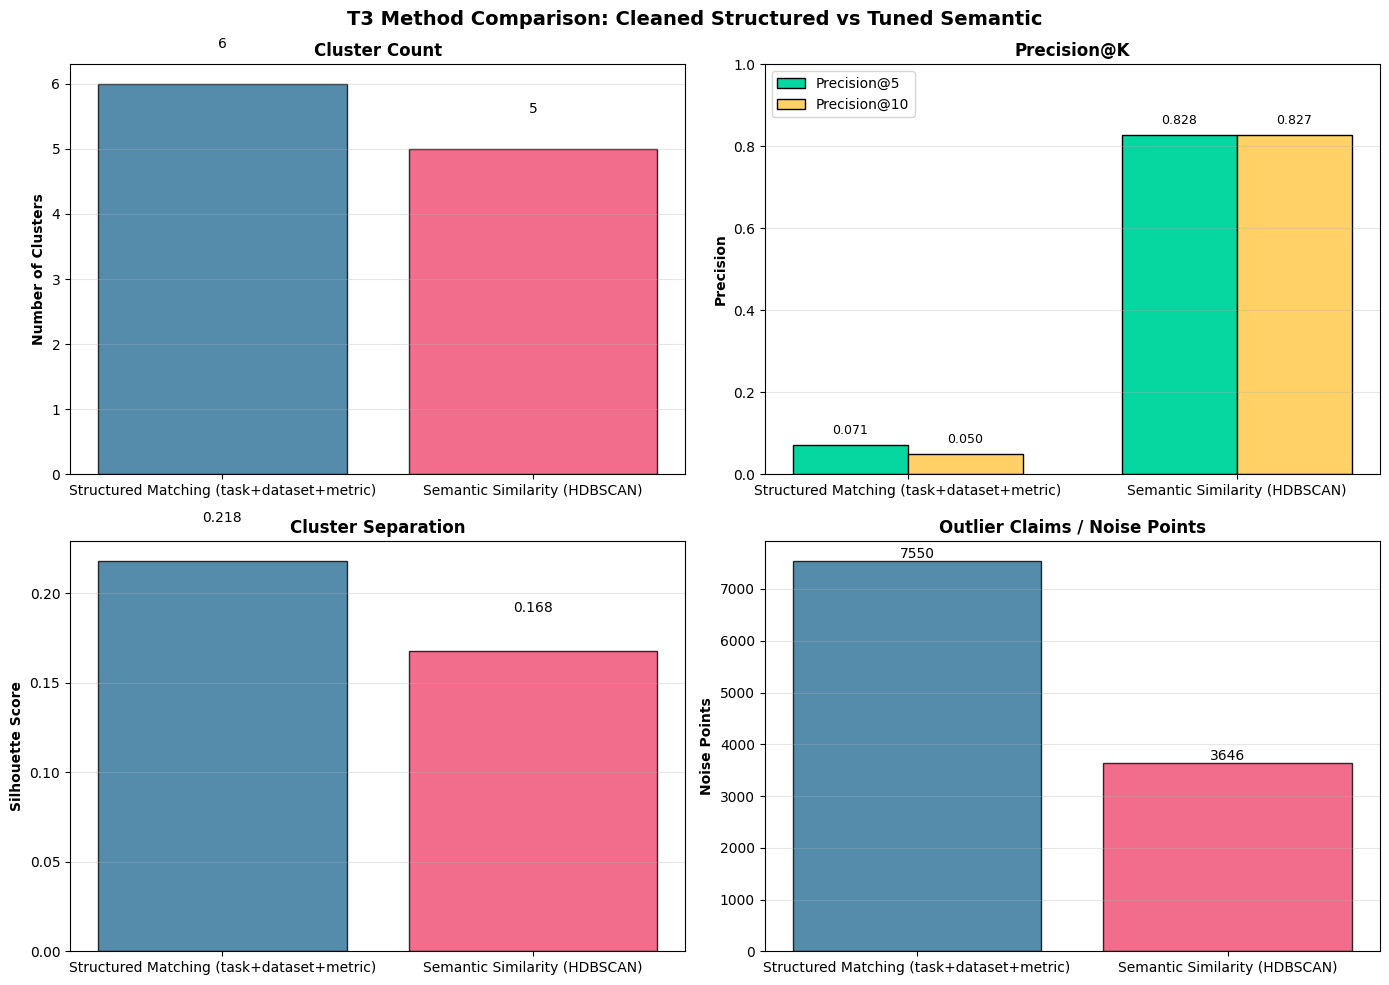

Saved plot: /work/Research/extracted/Nawazish_RnD/Notebook/outputs/t3/t3_method_comparison.png


In [11]:
# Visual comparison dashboard for T3 methods
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("T3 Method Comparison: Cleaned Structured vs Tuned Semantic", fontsize=14, fontweight="bold")

methods = df_comparison["Method"]

# 1) Number of clusters
ax = axes[0, 0]
clusters = df_comparison["Number of Clusters"]
bars = ax.bar(methods, clusters, color=["#2a6f97", "#ef476f"], alpha=0.8, edgecolor="black")
ax.set_ylabel("Number of Clusters", fontweight="bold")
ax.set_title("Cluster Count", fontweight="bold")
ax.grid(axis="y", alpha=0.3)
for bar, val in zip(bars, clusters):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.5, str(int(val)), ha="center", va="bottom")

# 2) Precision@K
ax = axes[0, 1]
x = np.arange(len(methods))
width = 0.35
bars_p5 = ax.bar(x - width / 2, df_comparison["Precision@5"], width, label="Precision@5", color="#06d6a0", edgecolor="black")
bars_p10 = ax.bar(x + width / 2, df_comparison["Precision@10"], width, label="Precision@10", color="#ffd166", edgecolor="black")
ax.set_ylabel("Precision", fontweight="bold")
ax.set_title("Precision@K", fontweight="bold")
ax.set_xticks(x)
ax.set_xticklabels(methods)
ax.set_ylim(0, 1.0)
ax.legend()
ax.grid(axis="y", alpha=0.3)
for bars_cur in [bars_p5, bars_p10]:
    for bar in bars_cur:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.02, f"{h:.3f}", ha="center", va="bottom", fontsize=9)

# 3) Silhouette
ax = axes[1, 0]
sil_vals = [s if s is not None else 0.0 for s in df_comparison["Silhouette Score"]]
bars = ax.bar(methods, sil_vals, color=["#2a6f97", "#ef476f"], alpha=0.8, edgecolor="black")
ax.set_ylabel("Silhouette Score", fontweight="bold")
ax.set_title("Cluster Separation", fontweight="bold")
ax.grid(axis="y", alpha=0.3)
for bar, val in zip(bars, sil_vals):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.02, f"{val:.3f}", ha="center", va="bottom")

# 4) Noise points
ax = axes[1, 1]
noise_vals = df_comparison["Noise Points"]
bars = ax.bar(methods, noise_vals, color=["#2a6f97", "#ef476f"], alpha=0.8, edgecolor="black")
ax.set_ylabel("Noise Points", fontweight="bold")
ax.set_title("Outlier Claims / Noise Points", fontweight="bold")
ax.grid(axis="y", alpha=0.3)
for bar, val in zip(bars, noise_vals):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.5, str(int(val)), ha="center", va="bottom")

plt.tight_layout()

plot_path = OUTPUT_T3_DIR / "t3_method_comparison.png"
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved plot: {plot_path}")

## Section 7: Unified Semantic + Performance Comparison

This section builds production-style T3 outputs from the cleaned strict groups:
1. **Strict cross-paper grouping**: `task + dataset + metric`, with at least 2 unique papers.
2. **Semantic coherence**: within-group embedding consistency from cosine similarity.
3. **Performance normalization**: parse values and normalize by metric direction.
4. **Optional temporal diagnostics**: yearly trend is calculated only when year/value information is available.
5. **Unified score**: weighted aggregate for ranking comparison groups.


In [12]:
# Unified comparison pipeline for semantic, performance, and evolution analysis

METRIC_DIRECTION = {
    "accuracy": "higher",
    "f1": "higher",
    "precision": "higher",
    "recall": "higher",
    "sensitivity": "higher",
    "specificity": "higher",
    "auc-roc": "higher",
    "c-index": "higher",
    "dice": "higher",
    "iou": "higher",
    "bleu": "higher",
    "rouge": "higher",
    "loss": "lower",
    "error": "lower",
    "mae": "lower",
    "mse": "lower",
    "rmse": "lower",
    "wer": "lower",
}


def parse_numeric_value_with_percent(value):
    if value is None:
        return None
    text = str(value).strip()
    if not text:
        return None

    match = re.search(r"[-+]?\d*\.?\d+", text.replace(",", ""))
    if not match:
        return None

    num = float(match.group())
    is_percent = "%" in text

    if is_percent:
        return num / 100.0
    return num


def normalize_for_metric(value_num, metric_name):
    if value_num is None:
        return None

    m = canonical_metric(metric_name)
    direction = METRIC_DIRECTION.get(m, "higher")

    # Normalize values commonly expressed as 0-100 percentages.
    if value_num > 1.0 and value_num <= 100.0:
        value_num = value_num / 100.0

    # Keep bounded values in [0, 1] where possible.
    clipped = max(0.0, min(1.0, value_num)) if value_num <= 1.0 else value_num

    if direction == "higher":
        if clipped <= 1.0:
            return clipped
        return 1.0 / (1.0 + clipped)

    # Convert lower-is-better to higher-is-better.
    if clipped <= 1.0:
        return 1.0 - clipped
    return 1.0 / (1.0 + clipped)


def build_strict_cross_paper_groups(claims):
    groups = defaultdict(list)
    for idx, claim in enumerate(claims):
        key = matcher.build_group_key(claim)
        if key is not None:
            groups[key].append(idx)

    strict = {}
    for key, indices in groups.items():
        paper_ids = {str(claims[i].get("paper_id", "unknown")) for i in indices}
        if len(indices) >= 2 and len(paper_ids) >= 2:
            strict[key] = {
                "indices": indices,
                "n_papers": len(paper_ids),
                "paper_ids": sorted(paper_ids),
            }
    return strict


def semantic_group_coherence(indices, sim_matrix):
    if len(indices) <= 1:
        return None
    sub = sim_matrix[np.ix_(indices, indices)]
    mask = ~np.eye(len(indices), dtype=bool)
    vals = sub[mask]
    if len(vals) == 0:
        return None
    return float(np.mean(vals))


def group_performance_stats(indices):
    normalized_scores = []
    by_model = defaultdict(list)

    for idx in indices:
        claim = claims_list[idx]
        model_name = claim.get("model") or "unknown_model"
        metric_name = claim.get("metric")
        raw_num = parse_numeric_value_with_percent(claim.get("value"))
        norm_score = normalize_for_metric(raw_num, metric_name)

        if norm_score is not None:
            normalized_scores.append(norm_score)
            by_model[model_name].append(norm_score)

    if not normalized_scores:
        return {
            "n_scored": 0,
            "median_score": None,
            "best_score": None,
            "spread": None,
            "model_ranking": [],
        }

    ranking = []
    for model_name, vals in by_model.items():
        ranking.append(
            {
                "model": model_name,
                "median_score": float(np.median(vals)),
                "best_score": float(np.max(vals)),
                "n_claims": len(vals),
            }
        )
    ranking.sort(key=lambda x: x["median_score"], reverse=True)

    spread = float(np.percentile(normalized_scores, 75) - np.percentile(normalized_scores, 25))

    return {
        "n_scored": int(len(normalized_scores)),
        "median_score": float(np.median(normalized_scores)),
        "best_score": float(np.max(normalized_scores)),
        "spread": spread,
        "model_ranking": ranking,
    }


def group_evolution_stats(indices):
    year_to_scores = defaultdict(list)

    for idx in indices:
        claim = claims_list[idx]
        year = claim.get("year")
        if year is None:
            continue

        try:
            y = int(year)
        except Exception:
            continue

        metric_name = claim.get("metric")
        raw_num = parse_numeric_value_with_percent(claim.get("value"))
        norm_score = normalize_for_metric(raw_num, metric_name)
        if norm_score is not None:
            year_to_scores[y].append(norm_score)

    if len(year_to_scores) == 0:
        return {
            "n_years": 0,
            "slope": None,
            "trend": "unknown",
            "yearly": [],
        }

    yearly = []
    for year in sorted(year_to_scores):
        vals = year_to_scores[year]
        yearly.append(
            {
                "year": year,
                "n": len(vals),
                "median": float(np.median(vals)),
                "best": float(np.max(vals)),
            }
        )

    if len(yearly) < 2:
        return {
            "n_years": len(yearly),
            "slope": None,
            "trend": "unknown",
            "yearly": yearly,
        }

    xs = np.array([r["year"] for r in yearly], dtype=float)
    ys = np.array([r["median"] for r in yearly], dtype=float)
    slope = float(np.polyfit(xs, ys, 1)[0])

    if slope > 0.01:
        trend = "improving"
    elif slope < -0.01:
        trend = "declining"
    else:
        trend = "stable"

    return {
        "n_years": len(yearly),
        "slope": slope,
        "trend": trend,
        "yearly": yearly,
    }


def safe01(v, default=0.0):
    if v is None:
        return default
    return float(max(0.0, min(1.0, v)))


strict_groups = build_strict_cross_paper_groups(claims_list)
print(f"Strict cross-paper groups: {len(strict_groups)}")

unified_rows = []
unified_details = []

for key, payload in strict_groups.items():
    task, dataset, metric = key
    indices = payload["indices"]

    coherence = semantic_group_coherence(indices, similarity_matrix)
    perf = group_performance_stats(indices)
    evol = group_evolution_stats(indices)

    # Weighted unified score prioritizing semantic coherence and performance.
    semantic_component = safe01(coherence)
    performance_component = safe01(perf.get("median_score"))
    evolution_component = safe01((evol.get("slope") or 0.0) * 10.0 + 0.5)

    unified_score = (
        0.45 * semantic_component
        + 0.40 * performance_component
        + 0.15 * evolution_component
    )

    group_id = f"task={task}&dataset={dataset}&metric={metric}"

    unified_rows.append(
        {
            "comparison_group_id": group_id,
            "task": task,
            "dataset": dataset,
            "metric": metric,
            "n_claims": len(indices),
            "n_papers": payload["n_papers"],
            "semantic_coherence": coherence,
            "performance_median": perf.get("median_score"),
            "performance_spread_iqr": perf.get("spread"),
            "evolution_slope": evol.get("slope"),
            "evolution_trend": evol.get("trend"),
            "unified_score": float(unified_score),
        }
    )

    unified_details.append(
        {
            "comparison_group_id": group_id,
            "task": task,
            "dataset": dataset,
            "metric": metric,
            "n_claims": len(indices),
            "n_papers": payload["n_papers"],
            "paper_ids": payload["paper_ids"],
            "semantic": {
                "coherence": coherence,
            },
            "performance": perf,
            "evolution": evol,
        }
    )

unified_df = pd.DataFrame(unified_rows)
if len(unified_df) > 0:
    unified_df = unified_df.sort_values("unified_score", ascending=False).reset_index(drop=True)

print("\nTop unified groups:")
print(unified_df.head(10).to_string(index=False))

OUTPUT_T3_DIR = WORKSPACE_ROOT / "outputs" / "t3"
OUTPUT_T3_DIR.mkdir(parents=True, exist_ok=True)

unified_csv_path = OUTPUT_T3_DIR / "comparison_unified.csv"
unified_json_path = OUTPUT_T3_DIR / "comparison_unified_detailed.json"

unified_df.to_csv(unified_csv_path, index=False)
with open(unified_json_path, "w", encoding="utf-8") as f:
    json.dump(unified_details, f, indent=2, ensure_ascii=False)

print(f"\nSaved: {unified_csv_path}")
print(f"Saved: {unified_json_path}")

Strict cross-paper groups: 6

Top unified groups:
                                                     comparison_group_id                      task         dataset           metric  n_claims  n_papers  semantic_coherence  performance_median  performance_spread_iqr evolution_slope evolution_trend  unified_score
                        task=segmentation&dataset=brats 2020&metric=dice              segmentation      brats 2020             dice         3         3            0.952513                0.95                     0.0            None         unknown       0.883631
task=survival prediction&dataset=glioma patients&metric=overall survival       survival prediction glioma patients overall survival         3         3            0.976366                 NaN                     NaN            None         unknown       0.514365
task=risk association analysis&dataset=glioma tissues&metric=association risk association analysis  glioma tissues      association         2         2          